# 71 ? Embeddings MPNet + K-Means e categoriza??o revisada

Este notebook investiga embeddings densos de descri??es de itens fiscais como representa??o alternativa ao TF-IDF do notebook 70. O fluxo segue a mesma l?gica: separar valida??o, comparar configura??es de clustering, inspecionar grupos, definir r?tulos humanos e avaliar a reserva.

Usa `sentence-transformers/paraphrase-multilingual-mpnet-base-v2`, variante multil?ngue baseada em MPNet, adequada para incluir portugu?s. O modelo gera um vetor por descri??o; K-Means agrupa esses vetores. MPNet ? um m?todo de pr?-treinamento de linguagem, n?o um autoencoder cl?ssico que reconstr?i a entrada.

**Como usar:** ajuste os par?metros e execute as c?lulas at? a revis?o. Depois edite `cluster_review.csv`, escolha um experimento e preencha `validation_labels.csv` antes de executar a avalia??o. A taxonomia depende de revis?o humana; o notebook n?o atribui categorias automaticamente.

A primeira execucao pode baixar o modelo do Hugging Face. `sentence-transformers` ja esta declarado nas dependencias do projeto. Cada execucao usa pastas novas para preservar os artefatos existentes.


In [1]:
from matplotlib.colors import ListedColormap
from sklearn.manifold import TSNE
from sklearn.decomposition import TruncatedSVD
import json
import logging
from datetime import datetime, timezone
from hashlib import sha256
from pathlib import Path
from uuid import uuid4

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn import config_context
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, calinski_harabasz_score,
                             classification_report, confusion_matrix,
                             davies_bouldin_score, silhouette_score)

try:
    from sentence_transformers import SentenceTransformer
except ImportError as exc:
    raise ImportError(
        "Nao foi possivel importar sentence-transformers do ambiente do projeto."
    ) from exc

from nofis_classifier.schema import DESCRIPTION_NORMALIZED, FREQUENCY

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
logger = logging.getLogger("notebook71")
pd.set_option("display.max_colwidth", 160)


## Configuracoes e comparabilidade

Controles comuns aos notebooks 70 a 76:

- Base completa `2025_NCMs_filtrados_semstopwords`, periodo 202501-202512.
- Ate 20.000 descricoes unicas para agrupamento, amostradas com semente 42 e ordenadas por descricao normalizada. Frequencia nao pondera o ajuste.
- Silhouette cosseno sobre uma amostra base fixa de ate 20.000 linhas, com semente 42. Ruido do algoritmo e excluido depois da amostragem; a quantidade efetivamente avaliada e registrada.
- Ranking exige silhouette definida e de 10 a 1.000 clusters efetivamente formados, sem contar ruido. Pesos: 0,75 para silhouette reescalada e 0,25 para cobertura do algoritmo.
- t-SNE 2D e 3D: mesmos ate 5.000 itens, semente 42, TruncatedSVD de ate 50 componentes, perplexidade 30, 1.000 iteracoes, init PCA (quando ha dimensoes suficientes), learning_rate auto e Barnes-Hut. As projecoes de representacoes diferentes sao exploratorias, nao um espaco comum de distancias.
- `comparison` em `run.json` registra os controles e o hash das descricoes/frequencias usadas no agrupamento.

MPNet: `sentence-transformers/paraphrase-multilingual-mpnet-base-v2`, batch_size 64, normalize_embeddings True e saida float32. Nao ha min_df ou analyzer no MPNet puro.

K-Means: k 20/50/100/200, semente 42, n_init 10, max_iter 300, algoritmo lloyd. O agrupamento usa as mesmas 20.000 descricoes dos outros notebooks. As 300 descricoes para validacao humana sao retiradas do complemento dessa amostra, antes da vetorizacao, e nunca participam do ajuste ou ranking. Quando a base e menor, e necessario preservar espaco para a reserva. K-Means atribui todos os itens, portanto sua cobertura e 1 e seu ruido e 0.

Grade atual: 4 valores de k = 4 ajustes. CH, DB e inercia permanecem como diagnosticos complementares.


In [2]:
RUN_ID = None  # Identificador opcional; None cria uma execucao nova.
DATASET_NAME = "2025_NCMs_filtrados_semstopwords"
PROJECT_ROOT = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "data" / "processed").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Nao encontrei a raiz do repositorio com data/processed/.")
DATASET_DIR = PROJECT_ROOT / "data" / "processed" / DATASET_NAME
DATASET_FILES = sorted(DATASET_DIR.glob("*.parquet"))
if not DATASET_FILES:
    raise FileNotFoundError(f"Nenhum Parquet encontrado para {DATASET_NAME}: {DATASET_DIR}")
if len(DATASET_FILES) > 1:
    raise ValueError(
        f"Mais de um Parquet encontrado em {DATASET_DIR}; selecione o arquivo/periodo explicitamente: "
        f"{[path.name for path in DATASET_FILES]}"
    )
DATASET_PATH = DATASET_FILES[0]
if not DATASET_PATH.stem.startswith(f"{DATASET_NAME}-"):
    raise ValueError(
        f"O nome do arquivo deve comecar com '{DATASET_NAME}-' para derivar o periodo: "
        f"{DATASET_PATH.name}"
    )
PERIOD_LABEL = DATASET_PATH.stem[len(DATASET_NAME) + 1:]
MODEL_NAME = "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
MAX_DESCRIPTIONS = 20_000
CONSIDER_FREQUENCY_IN_CLUSTERING = False
VALIDATION_COUNT = 300
SPLIT_SEED = 42
K_VALUES = [20, 50, 100, 200]
SEEDS = [42]
N_INIT = 10
MAX_ITER = 300
SILHOUETTE_SAMPLE_SIZE = 20_000
METRIC_SAMPLE_SIZE = SILHOUETTE_SAMPLE_SIZE
PAIRWISE_WORKING_MEMORY_MIB = 64


MAX_CLUSTERS_FOR_RANKING = 1000
MIN_CLUSTER_FOR_RANKING = 10
SILHOUETTE_WEIGHT = 0.75
NOISE_WEIGHT = 0.25

TOP_COMBINATIONS = 3
ENCODE_BATCH_SIZE = 64
REPORT_ROOT = PROJECT_ROOT / "reports/mpnet_kmeans"
MODEL_ROOT = PROJECT_ROOT / "models/mpnet_kmeans"


METRIC_RANDOM_STATE = 42

TSNE_MAX_POINTS = 5_000

TSNE_PERPLEXITY = 30

TSNE_MAX_ITER = 1_000

TSNE_RANDOM_STATE = 42

TSNE_SVD_COMPONENTS = 50

TSNE_3D_N_COMPONENTS = 3


In [3]:
def compute_tsne_projection(features, max_points, perplexity, max_iter, random_state, n_components=2):
    """Usa a mesma amostra, SVD e parametros t-SNE em todas as representacoes."""
    point_count = features.shape[0]
    sample_count = min(point_count, max_points)
    if sample_count < 3 or n_components not in (2, 3):
        raise ValueError("t-SNE exige pelo menos tres itens e n_components 2 ou 3.")
    rng = np.random.default_rng(random_state)
    indices = np.sort(rng.choice(point_count, size=sample_count, replace=False))
    sampled = features[indices]
    dimensions = min(TSNE_SVD_COMPONENTS, sampled.shape[1] - 1, sample_count - 1)
    if dimensions >= 1:
        reduced = TruncatedSVD(n_components=dimensions, random_state=random_state).fit_transform(sampled)
    else:
        reduced = sampled.toarray() if hasattr(sampled, "toarray") else np.asarray(sampled)
        dimensions = reduced.shape[1]
    coordinates = TSNE(
        n_components=n_components,
        perplexity=min(float(perplexity), (sample_count - 1) / 3),
        init="pca" if dimensions >= n_components else "random",
        learning_rate="auto", max_iter=max_iter, random_state=random_state,
        method="barnes_hut",
    ).fit_transform(reduced)
    return indices, coordinates, dimensions

def save_tsne_plot(coordinates, labels, run_id, output_path):
    """Salva um PNG t-SNE colorido pelos clusters, com o ru?do em cinza."""
    labels = np.asarray(labels)
    noise_mask = labels == -1
    cluster_ids = np.unique(labels[~noise_mask])
    if cluster_ids.size:
        palette = plt.get_cmap("tab20").colors
        cluster_cmap = ListedColormap([
            palette[index % len(palette)] for index in range(len(cluster_ids))
        ])
        cluster_codes = np.searchsorted(cluster_ids, labels[~noise_mask])
    else:
        cluster_cmap = None
        cluster_codes = np.empty(0, dtype=int)

    figure, axis = plt.subplots(figsize=(11, 8), constrained_layout=True)
    if noise_mask.any():
        axis.scatter(
            coordinates[noise_mask, 0], coordinates[noise_mask, 1],
            c="#b8b8b8", s=8, alpha=0.3, linewidths=0,
        )
    if cluster_ids.size:
        axis.scatter(
            coordinates[~noise_mask, 0], coordinates[~noise_mask, 1],
            c=cluster_codes, cmap=cluster_cmap, vmin=-0.5,
            vmax=len(cluster_ids) - 0.5, s=9, alpha=0.75, linewidths=0,
        )
    axis.set_title(
        f"t-SNE: {run_id}\n{len(cluster_ids)} clusters; "
        f"{int(noise_mask.sum()):,} descri??es como ru?do"
    )
    axis.set_xlabel("t-SNE 1")
    axis.set_ylabel("t-SNE 2")
    axis.text(
        0.01, 0.01,
        "Ru?do em cinza; as cores se repetem a cada 20 clusters.",
        transform=axis.transAxes, fontsize=8, color="#555555",
    )
    figure.savefig(output_path, dpi=160)
    plt.close(figure)

def save_tsne_3d_html(coordinates, labels, run_id, output_path):
    """Salva uma visualiza??o t-SNE 3D interativa e autocontida em HTML."""
    points = [
        {"x": float(x), "y": float(y), "z": float(z), "label": int(label)}
        for (x, y, z), label in zip(coordinates, labels)
    ]
    data_json = json.dumps(points, separators=(",", ":"))
    title = str(run_id).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    page = r"""<!doctype html>
<html lang="pt-BR">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>t-SNE 3D: __TITLE__</title>
<style>
html, body { margin: 0; height: 100%; background: #f7f8fa; color: #202124; font: 14px system-ui, sans-serif; }
main { display: flex; flex-direction: column; height: 100%; }
header { padding: 12px 18px; background: white; border-bottom: 1px solid #ddd; }
h1 { margin: 0 0 4px; font-size: 17px; }
p { margin: 0; color: #555; }
canvas { display: block; width: 100%; flex: 1; min-height: 300px; cursor: grab; }
canvas:active { cursor: grabbing; }
</style>
</head>
<body>
<main>
<header><h1>Proje??o t-SNE 3D: __TITLE__</h1><p>Arraste para girar; use a roda do mouse para aproximar. Ru?do em cinza.</p></header>
<canvas id="plot"></canvas>
</main>
<script>
const points = __POINTS__;
const canvas = document.getElementById("plot");
const ctx = canvas.getContext("2d");
let yaw = 0.65, pitch = -0.35, zoom = 1, dragging = false, lastX = 0, lastY = 0;
const colors = ["#3366cc", "#dc3912", "#ff9900", "#109618", "#990099", "#0099c6", "#dd4477", "#66aa00", "#b82e2e", "#316395", "#994499", "#22aa99", "#aaaa11", "#6633cc", "#e67300", "#8b0707", "#651067", "#329262", "#5574a6", "#3b3eac"];
const bounds = ["x", "y", "z"].map(key => {
  const values = points.map(point => point[key]);
  const low = Math.min(...values), high = Math.max(...values);
  return { low, span: Math.max(high - low, 1e-9) };
});
function resize() {
  const ratio = window.devicePixelRatio || 1;
  canvas.width = Math.max(1, Math.floor(canvas.clientWidth * ratio));
  canvas.height = Math.max(1, Math.floor(canvas.clientHeight * ratio));
  ctx.setTransform(ratio, 0, 0, ratio, 0, 0);
  draw();
}
function draw() {
  const width = canvas.clientWidth, height = canvas.clientHeight;
  ctx.clearRect(0, 0, width, height);
  const scale = Math.min(width, height) * 0.7 * zoom;
  const cy = Math.cos(yaw), sy = Math.sin(yaw), cp = Math.cos(pitch), sp = Math.sin(pitch);
  const projected = points.map(point => {
    const x = ((point.x - bounds[0].low) / bounds[0].span - 0.5) * 2;
    const y = ((point.y - bounds[1].low) / bounds[1].span - 0.5) * 2;
    const z = ((point.z - bounds[2].low) / bounds[2].span - 0.5) * 2;
    const rx = x * cy - z * sy, rz = x * sy + z * cy;
    const ry = y * cp - rz * sp, depth = y * sp + rz * cp;
    return { x: width / 2 + rx * scale / 2, y: height / 2 - ry * scale / 2, depth, label: point.label };
  }).sort((a, b) => a.depth - b.depth);
  for (const point of projected) {
    ctx.globalAlpha = point.label === -1 ? 0.24 : 0.78;
    ctx.fillStyle = point.label === -1 ? "#999999" : colors[Math.abs(point.label) % colors.length];
    ctx.beginPath();
    ctx.arc(point.x, point.y, point.label === -1 ? 2 : 3, 0, Math.PI * 2);
    ctx.fill();
  }
  ctx.globalAlpha = 1;
}
canvas.addEventListener("pointerdown", event => { dragging = true; lastX = event.clientX; lastY = event.clientY; canvas.setPointerCapture(event.pointerId); });
canvas.addEventListener("pointerup", () => { dragging = false; });
canvas.addEventListener("pointermove", event => {
  if (!dragging) return;
  yaw += (event.clientX - lastX) * 0.008;
  pitch = Math.max(-1.5, Math.min(1.5, pitch + (event.clientY - lastY) * 0.008));
  lastX = event.clientX; lastY = event.clientY; draw();
});
canvas.addEventListener("wheel", event => { event.preventDefault(); zoom = Math.max(0.3, Math.min(5, zoom * (event.deltaY < 0 ? 1.1 : 0.9))); draw(); }, { passive: false });
window.addEventListener("resize", resize);
resize();
</script>
</body>
</html>"""
    page = page.replace("__TITLE__", title).replace("__POINTS__", data_json)
    output_path.write_text(page, encoding="utf-8")

def comparison_metadata(frame):
    """Registra controles comuns e a identidade exata da amostra de agrupamento."""
    sample = frame[[DESCRIPTION_NORMALIZED, FREQUENCY]].sort_values(DESCRIPTION_NORMALIZED).reset_index(drop=True)
    return {
        "dataset_name": DATASET_NAME,
        "training_description_count": len(sample),
        "training_sample_sha256": sha256(pd.util.hash_pandas_object(sample, index=False).values.tobytes()).hexdigest(),
        "max_descriptions": MAX_DESCRIPTIONS, "sample_seed": 42,
        "frequency_weighted": False,
        "silhouette_metric": "cosine", "silhouette_sample_size": SILHOUETTE_SAMPLE_SIZE,
        "metric_random_state": METRIC_RANDOM_STATE,
        "metric_sampling": "fixed rows, then exclude algorithmic noise",
        "min_cluster_for_ranking": MIN_CLUSTER_FOR_RANKING,
        "max_clusters_for_ranking": MAX_CLUSTERS_FOR_RANKING,
        "silhouette_weight": SILHOUETTE_WEIGHT, "noise_weight": NOISE_WEIGHT,
        "tsne": {
            "max_points": TSNE_MAX_POINTS, "perplexity": TSNE_PERPLEXITY,
            "max_iter": TSNE_MAX_ITER, "random_state": TSNE_RANDOM_STATE,
            "reduction": "TruncatedSVD", "svd_components": TSNE_SVD_COMPONENTS,
            "dimensions": [2, 3], "init": "pca", "learning_rate": "auto",
            "method": "barnes_hut",
        },
    }


## 2. Carregar, dividir e gerar embeddings

A amostra de agrupamento tem ate 20.000 descricoes. A reserva de 300 vem do complemento da amostra e e identica a do notebook 70. Os embeddings da reserva ficam separados e nao entram no treinamento, nas metricas internas ou no ranking.


In [4]:
items = pd.read_parquet(DATASET_PATH)
required = [DESCRIPTION_NORMALIZED, FREQUENCY]
missing = set(required) - set(items.columns)
if missing:
    raise ValueError(f"Colunas ausentes: {sorted(missing)}")
frequency_before = items[FREQUENCY].sum()
items[DESCRIPTION_NORMALIZED] = items[DESCRIPTION_NORMALIZED].astype("string").str.strip()
items = items[items[DESCRIPTION_NORMALIZED].notna() & items[DESCRIPTION_NORMALIZED].ne("")]
items = items[items[FREQUENCY] >= 1].copy()
items = (
    items.groupby(DESCRIPTION_NORMALIZED, as_index=False, sort=False)[FREQUENCY]
    .sum()
)
if items[FREQUENCY].sum() != frequency_before:
    raise ValueError("A soma de frequ?ncia mudou durante a prepara??o.")
items = items.sort_values(DESCRIPTION_NORMALIZED).reset_index(drop=True)
items.insert(0, "descricao_id", np.arange(len(items), dtype=np.int64))
if not 0 < VALIDATION_COUNT < len(items) - 1:
    raise ValueError("A base deve comportar treino e reserva disjuntos.")
training_count = len(items) - VALIDATION_COUNT if MAX_DESCRIPTIONS is None else min(MAX_DESCRIPTIONS, len(items) - VALIDATION_COUNT)
train = items.sample(n=training_count, random_state=SPLIT_SEED)
validation = items.drop(train.index).sample(n=VALIDATION_COUNT, random_state=SPLIT_SEED)
train = train.sort_values(DESCRIPTION_NORMALIZED).reset_index(drop=True)
validation = validation.sort_values(DESCRIPTION_NORMALIZED).reset_index(drop=True)
items = pd.concat([train, validation], ignore_index=True).sort_values("descricao_id").reset_index(drop=True)
assert set(train[DESCRIPTION_NORMALIZED]).isdisjoint(validation[DESCRIPTION_NORMALIZED])
assert all(2 <= k < len(train) for k in K_VALUES)


RUN_ID = RUN_ID or datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
if not all(c.isalnum() or c in "_-" for c in RUN_ID):
    raise ValueError("RUN_ID inv?lido.")
REPORT_DIR = REPORT_ROOT / f"{PERIOD_LABEL}_{RUN_ID}"
MODEL_DIR = MODEL_ROOT / f"{PERIOD_LABEL}_{RUN_ID}"
REPORT_DIR.mkdir(parents=True, exist_ok=False)
MODEL_DIR.mkdir(parents=True, exist_ok=False)

metadata = {
    "comparison": comparison_metadata(train),
    "run_id": RUN_ID, "dataset": DATASET_NAME, "period": PERIOD_LABEL,
    "frequency_weighted": CONSIDER_FREQUENCY_IN_CLUSTERING,
    "dataset_sha256": sha256(pd.util.hash_pandas_object(items, index=True).values.tobytes()).hexdigest(),
    "model_name": MODEL_NAME, "validation_count": VALIDATION_COUNT,
    "split_seed": SPLIT_SEED, "k_values": K_VALUES, "seeds": SEEDS,
    "max_descriptions": MAX_DESCRIPTIONS, "dataset_path": str(DATASET_PATH),
    "sample_count": len(train), "training_count": len(train),
    "n_init": N_INIT, "max_iter": MAX_ITER, "metric_sample_size": METRIC_SAMPLE_SIZE,
    "pairwise_working_memory_mib": PAIRWISE_WORKING_MEMORY_MIB,
    "max_clusters_for_ranking": MAX_CLUSTERS_FOR_RANKING,
    "min_cluster_for_ranking": MIN_CLUSTER_FOR_RANKING,
    "silhouette_weight": SILHOUETTE_WEIGHT, "noise_weight": NOISE_WEIGHT,
}
(REPORT_DIR / "run.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
train.to_csv(REPORT_DIR / "training_descriptions.csv", index=False)
validation[["descricao_id", DESCRIPTION_NORMALIZED, FREQUENCY]].assign(
    categoria_esperada="", observacoes=""
).to_csv(REPORT_DIR / "heldout_descriptions.csv", index=False)

experiment_matrix = pd.DataFrame([
    {"k": k, "seed": seed, "n_init": N_INIT}
    for k in K_VALUES for seed in SEEDS
])
experiment_matrix.to_csv(REPORT_DIR / "planned_grid.csv", index=False)
logger.info("Grade planejada: %d ajustes", len(experiment_matrix))

logger.info("Carregando modelo %s", MODEL_NAME)
encoder = SentenceTransformer(MODEL_NAME)
train_embeddings = encoder.encode(
    train[DESCRIPTION_NORMALIZED].astype(str).tolist(), batch_size=ENCODE_BATCH_SIZE,
    show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=True,
).astype(np.float32)
validation_embeddings = encoder.encode(
    validation[DESCRIPTION_NORMALIZED].astype(str).tolist(), batch_size=ENCODE_BATCH_SIZE,
    show_progress_bar=True, convert_to_numpy=True, normalize_embeddings=True,
).astype(np.float32)
np.save(MODEL_DIR / "train_embeddings.npy", train_embeddings)
np.save(MODEL_DIR / "validation_embeddings.npy", validation_embeddings)
logger.info("Embeddings gerados: treino=%s valida??o=%s", train_embeddings.shape, validation_embeddings.shape)
display(pd.DataFrame({"particao": ["treino", "valida??o"],
                      "descri??es": [len(train), len(validation)],
                      "frequencia_total": [train[FREQUENCY].sum(), validation[FREQUENCY].sum()]}))


2026-10-24 18:16:00,051 INFO Grade planejada: 4 ajustes


2026-10-24 18:16:00,052 INFO Carregando modelo sentence-transformers/paraphrase-multilingual-mpnet-base-v2


2026-10-24 18:16:00,054 INFO No device provided, using cpu


2026-10-24 18:16:00,072 INFO Loading SentenceTransformer model from sentence-transformers/paraphrase-multilingual-mpnet-base-v2.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/313 [00:00<?, ?it/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

2026-10-24 18:19:28,737 INFO Embeddings gerados: treino=(20000, 768) valida??o=(300, 768)


,particao,descri??es,frequencia_total
0,treino,20000,117883
1,valida??o,300,3761


## 3. Executar a grade de K-Means

Cada combina??o de `k` e semente recebe um modelo pr?prio. Silhouette cosseno ? calculada em uma amostra fixa; CH e DB usam essa mesma amostra. A in?rcia ? apresentada apenas como diagn?stico dentro deste espa?o e desta execu??o. Arquivos de modelo s?o gravados em uma pasta nova por execu??o.


In [5]:
if SILHOUETTE_WEIGHT < 0 or NOISE_WEIGHT < 0 or SILHOUETTE_WEIGHT + NOISE_WEIGHT <= 0:
    raise ValueError("Os pesos devem ser nao negativos e pelo menos um deve ser maior que zero.")

sample_rng = np.random.default_rng(METRIC_RANDOM_STATE)
metric_positions = np.sort(sample_rng.choice(
    len(train_embeddings), size=min(METRIC_SAMPLE_SIZE, len(train_embeddings)), replace=False
))
metric_vectors = train_embeddings[metric_positions]
metric_rows = []
for k in K_VALUES:
    for seed in SEEDS:
        experiment_id = f"mpnet_k{k}_seed{seed}"
        logger.info("Ajustando %s", experiment_id)
        model = KMeans(n_clusters=k, random_state=seed, n_init=N_INIT,
                       max_iter=MAX_ITER, algorithm="lloyd")
        sample_weight = (
            train[FREQUENCY].to_numpy(dtype=float)
            if CONSIDER_FREQUENCY_IN_CLUSTERING else None
        )
        model.fit(train_embeddings, sample_weight=sample_weight)
        labels = model.labels_
        sample_labels = labels[metric_positions]
        unique_sample_labels = np.unique(sample_labels)
        with config_context(working_memory=PAIRWISE_WORKING_MEMORY_MIB):
            silhouette = (silhouette_score(metric_vectors, sample_labels, metric="cosine")
                          if 2 <= len(unique_sample_labels) < len(metric_positions) else np.nan)
            ch = (calinski_harabasz_score(metric_vectors, sample_labels)
                  if 2 <= len(unique_sample_labels) < len(metric_positions) else np.nan)
            db = (davies_bouldin_score(metric_vectors, sample_labels)
                  if 2 <= len(unique_sample_labels) < len(metric_positions) else np.nan)
        model_path = MODEL_DIR / f"{experiment_id}.pkl"
        pd.to_pickle(model, model_path)
        metric_rows.append({
            "experiment_id": experiment_id, "k": k, "seed": seed,
            "frequency_weighted": CONSIDER_FREQUENCY_IN_CLUSTERING,
            "silhouette_cosine": silhouette,
            "silhouette_cosine_without_noise": silhouette,
            "silhouette_base_sample_size": len(metric_positions),
            "noise_count": 0,
            "cluster_count_excluding_noise": len(np.unique(model.labels_)), "calinski_harabasz": ch,
            "davies_bouldin": db, "inertia": model.inertia_,
            "iterations": model.n_iter_, "largest_cluster_fraction": float(np.bincount(labels).max() / len(labels)),
            "sample_clusters": len(unique_sample_labels), "model_path": str(model_path),
            "silhouette_sample_size": len(metric_positions) if np.isfinite(silhouette) else 0,
            "cluster_count": len(np.unique(labels)), "noise_fraction": 0.0,
            "feature_count": train_embeddings.shape[1],
            "status": "ok",
        })
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(REPORT_DIR / "metrics.csv", index=False)
display(metrics)


2026-10-24 18:19:28,824 INFO Ajustando mpnet_k20_seed42


2026-10-24 18:19:55,124 INFO Ajustando mpnet_k50_seed42


2026-10-24 18:20:47,591 INFO Ajustando mpnet_k100_seed42


2026-10-24 18:22:11,036 INFO Ajustando mpnet_k200_seed42


,experiment_id,k,seed,frequency_weighted,silhouette_cosine,silhouette_cosine_without_noise,silhouette_base_sample_size,noise_count,cluster_count_excluding_noise,calinski_harabasz,...,inertia,iterations,largest_cluster_fraction,sample_clusters,model_path,silhouette_sample_size,cluster_count,noise_fraction,feature_count,status
0,mpnet_k20_seed42,20,42,False,0.093744,0.093744,20000,0,20,424.281005,...,8743.731445,79,0.07245,20,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\mpnet_kmeans\202501-202512_20261024T211600Z_cb2c9e42\mpnet_k20_seed42.pkl,20000,20,0.0,768,ok
1,mpnet_k50_seed42,50,42,False,0.108233,0.108233,20000,0,50,234.038890,...,7792.302246,175,0.04125,50,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\mpnet_kmeans\202501-202512_20261024T211600Z_cb2c9e42\mpnet_k50_seed42.pkl,20000,50,0.0,768,ok
2,mpnet_k100_seed42,100,42,False,0.109080,0.109080,20000,0,100,147.637018,...,7075.088379,67,0.02495,100,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\mpnet_kmeans\202501-202512_20261024T211600Z_cb2c9e42\mpnet_k100_seed42.pkl,20000,100,0.0,768,ok
3,mpnet_k200_seed42,200,42,False,0.116507,0.116507,20000,0,200,92.704100,...,6352.652344,75,0.01155,200,C:\Users\samuel.simao\Sources\Nofis-Classifier\models\mpnet_kmeans\202501-202512_20261024T211600Z_cb2c9e42\mpnet_k200_seed42.pkl,20000,200,0.0,768,ok


## 4. Comparar resultados e selecionar candidatos

O ranking usa a mesma formula composta dos outros experimentos, exige silhouette definida e todas as sementes, e filtra a quantidade efetivamente formada de clusters pelo intervalo configurado. A cobertura de K-Means e constante em 1. CH, DB e inercia sao diagnosticos adicionais. As categorias continuam dependendo da revisao humana.


,rank,k,silhouette_median,silhouette_std,noise_fraction_median,composite_score_median,seed_count,cluster_count_min,cluster_count_max,ch_median,db_median,inertia_median,largest_cluster_fraction
0,1,200,0.116507,NaN,0.0,0.668690,1,200,200,92.704100,2.751903,6352.652344,0.01155
1,2,100,0.109080,NaN,0.0,0.665905,1,100,100,147.637018,2.786195,7075.088379,0.02495
2,3,50,0.108233,NaN,0.0,0.665588,1,50,50,234.038890,2.898961,7792.302246,0.04125
3,4,20,0.093744,NaN,0.0,0.660154,1,20,20,424.281005,3.199318,8743.731445,0.07245


C:\Users\SAMUEL~1.SIM\AppData\Local\Temp\ipykernel_31624\4212125218.py:52: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


,experiment_id,k,seed,silhouette_cosine,composite_score,noise_fraction,calinski_harabasz,davies_bouldin,largest_cluster_fraction
0,mpnet_k200_seed42,200,42,0.116507,0.668690,0.0,92.704100,2.751903,0.01155
1,mpnet_k100_seed42,100,42,0.109080,0.665905,0.0,147.637018,2.786195,0.02495
2,mpnet_k50_seed42,50,42,0.108233,0.665588,0.0,234.038890,2.898961,0.04125


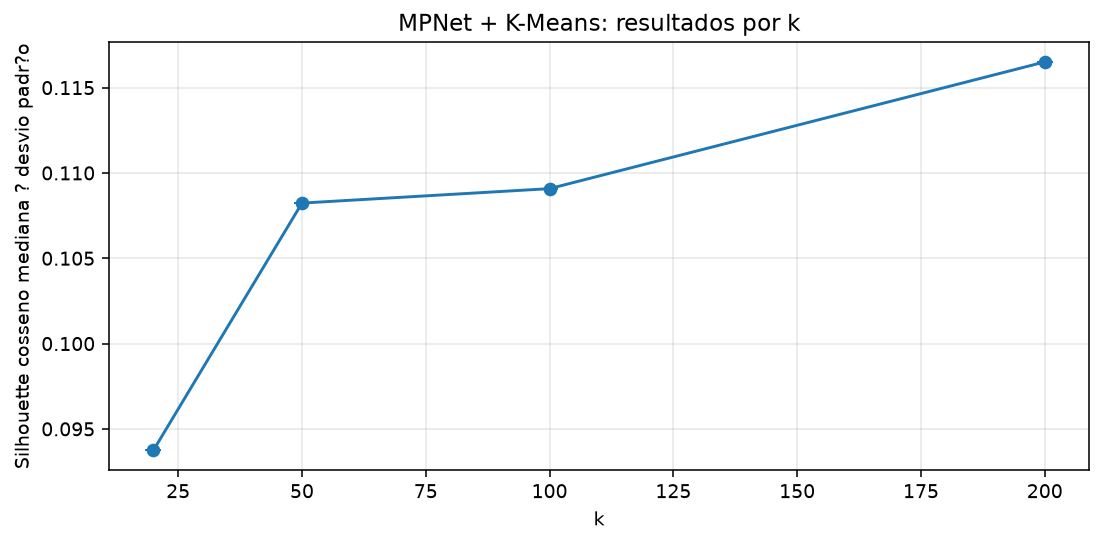

In [6]:
if not 1 <= MIN_CLUSTER_FOR_RANKING <= MAX_CLUSTERS_FOR_RANKING:
    raise ValueError(
        "Os limites devem atender a 1 <= MIN_CLUSTER_FOR_RANKING <= MAX_CLUSTERS_FOR_RANKING."
    )

metrics["silhouette_quality"] = (metrics["silhouette_cosine"] + 1) / 2
# K-Means atribui todos os embeddings; cobertura do agrupamento e constante.
metrics["noise_quality"] = 1 - metrics["noise_fraction"]
weight_total = SILHOUETTE_WEIGHT + NOISE_WEIGHT
metrics["composite_score"] = (
    SILHOUETTE_WEIGHT * metrics["silhouette_quality"]
    + NOISE_WEIGHT * metrics["noise_quality"]
) / weight_total
metrics.to_csv(REPORT_DIR / "metrics.csv", index=False)

ranking = (metrics.groupby("k", as_index=False)
           .agg(silhouette_median=("silhouette_cosine", "median"),
                silhouette_std=("silhouette_cosine", "std"),
                noise_fraction_median=("noise_fraction", "median"),
                composite_score_median=("composite_score", "median"),
                seed_count=("seed", "nunique"),
    cluster_count_min=("cluster_count", "min"),
    cluster_count_max=("cluster_count", "max"),
                ch_median=("calinski_harabasz", "median"),
                db_median=("davies_bouldin", "median"),
                inertia_median=("inertia", "median"),
                largest_cluster_fraction=("largest_cluster_fraction", "median")))
ranking = ranking[
    ranking.seed_count.eq(len(SEEDS)) & ranking.silhouette_median.notna()
    & ranking.cluster_count_min.ge(MIN_CLUSTER_FOR_RANKING)
    & ranking.cluster_count_max.le(MAX_CLUSTERS_FOR_RANKING)
].sort_values(
    ["composite_score_median", "silhouette_median", "noise_fraction_median"],
    ascending=[False, False, True], na_position="last",
).reset_index(drop=True)
if ranking.empty:
    raise RuntimeError(
        f"Nenhuma combinacao elegivel entre {MIN_CLUSTER_FOR_RANKING} e "
        f"{MAX_CLUSTERS_FOR_RANKING} clusters; verifique a grade e a silhouette."
    )
ranking.insert(0, "rank", range(1, len(ranking) + 1))
ranking.to_csv(REPORT_DIR / "ranking.csv", index=False)
display(ranking)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(ranking.k, ranking.silhouette_median, yerr=ranking.silhouette_std.fillna(0),
            marker="o", capsize=4)
ax.set(xlabel="k", ylabel="Silhouette cosseno mediana ? desvio padr?o",
       title="MPNet + K-Means: resultados por k")
ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig(REPORT_DIR / "silhouette_by_k.png", dpi=140, bbox_inches="tight")
plt.show()

candidate_ks = ranking.head(TOP_COMBINATIONS).k.tolist()
candidate_rows = []
for k in candidate_ks:
    group = metrics[metrics.k.eq(k)].copy()
    median = group.composite_score.median()
    chosen = group.loc[(group.composite_score - median).abs().idxmin()]
    candidate_rows.append(chosen)
candidates = pd.DataFrame(candidate_rows).reset_index(drop=True)
candidates.to_csv(REPORT_DIR / "candidates.csv", index=False)
display(candidates[["experiment_id", "k", "seed", "silhouette_cosine",
                    "composite_score", "noise_fraction",
                    "calinski_harabasz", "davies_bouldin", "largest_cluster_fraction"]])


## 5. Inspecionar descri??es e revisar clusters

Para cada candidato, o CSV de revis?o re?ne tamanho e frequ?ncia total dos clusters, al?m de descri??es centrais e amostras. Preencha `avaliacao_qualitativa` (`coerente`, `parcialmente coerente` ou `heterogeneo`), `rotulo_humano` e `observacoes`. Os arquivos existentes n?o s?o sobrescritos. O ?ndice e o modelo de cluster valem apenas para aquela execu??o.


In [7]:
tsne_indices, tsne_coordinates, _ = compute_tsne_projection(train_embeddings, TSNE_MAX_POINTS, TSNE_PERPLEXITY, TSNE_MAX_ITER, TSNE_RANDOM_STATE)
tsne_3d_indices, tsne_3d_coordinates, _ = compute_tsne_projection(train_embeddings, TSNE_MAX_POINTS, TSNE_PERPLEXITY, TSNE_MAX_ITER, TSNE_RANDOM_STATE, n_components=TSNE_3D_N_COMPONENTS)
assert np.array_equal(tsne_indices, tsne_3d_indices)
projection_frame = train.iloc[tsne_indices][[DESCRIPTION_NORMALIZED, FREQUENCY]].copy()
projection_frame[["tsne_1", "tsne_2"]] = tsne_coordinates
projection_frame[["tsne_3d_1", "tsne_3d_2", "tsne_3d_3"]] = tsne_3d_coordinates
projection_frame.to_csv(REPORT_DIR / "tsne_coordinates.csv", index=False)

for row in candidates.itertuples(index=False):
    model = pd.read_pickle(row.model_path)
    labels = model.labels_
    assigned = train[["descricao_id", DESCRIPTION_NORMALIZED, FREQUENCY]].copy()
    assigned["cluster"] = labels
    candidate_dir = REPORT_DIR / "review" / row.experiment_id
    candidate_dir.mkdir(parents=True, exist_ok=True)
    assignments_path = candidate_dir / "assignments.csv"
    if not assignments_path.exists():
        assigned.to_csv(assignments_path, index=False)
    cluster_rows = []
    for cluster_id in sorted(np.unique(labels)):
        positions = np.flatnonzero(labels == cluster_id)
        distances = np.linalg.norm(train_embeddings[positions] - model.cluster_centers_[cluster_id], axis=1)
        central_order = positions[np.argsort(distances)[:3]]
        rng = np.random.default_rng(SPLIT_SEED + int(cluster_id))
        random_positions = rng.choice(positions, size=min(2, len(positions)), replace=False)
        examples = list(dict.fromkeys(train.iloc[np.r_[central_order, random_positions]][DESCRIPTION_NORMALIZED].astype(str)))
        cluster_rows.append({
            "cluster": int(cluster_id), "descricoes_unicas": int(len(positions)),
            "frequencia_total": int(train.iloc[positions][FREQUENCY].sum()),
            "exemplos_representativos": " | ".join(examples),
            "avaliacao_qualitativa": "", "rotulo_humano": "", "observacoes": "",
        })
    review_frame = pd.DataFrame(cluster_rows)
    review_by_frequency_path = candidate_dir / "cluster_review_by_frequency.csv"
    if not review_by_frequency_path.exists():
        review_frame.sort_values("frequencia_total", ascending=False).to_csv(
            review_by_frequency_path, index=False
        )
    singleton_clusters = review_frame.loc[review_frame["descricoes_unicas"].eq(1), "cluster"]
    frequent_singletons = assigned[assigned["cluster"].isin(singleton_clusters)].sort_values(
        FREQUENCY, ascending=False
    )
    singleton_path = candidate_dir / "frequent_singleton_descriptions.csv"
    if not singleton_path.exists():
        frequent_singletons.to_csv(singleton_path, index=False)

    review_path = candidate_dir / "cluster_review.csv"
    if not review_path.exists():
        review_frame.to_csv(review_path, index=False)
    logger.info("Materiais de revis?o: %s", candidate_dir)
    display(pd.read_csv(review_by_frequency_path).head(5))
    display(frequent_singletons.head(20))

    save_tsne_plot(tsne_coordinates, labels[tsne_indices], row.experiment_id, candidate_dir / "tsne.png")
    save_tsne_3d_html(tsne_3d_coordinates, labels[tsne_indices], row.experiment_id, candidate_dir / "tsne_3d.html")


2026-10-24 18:25:38,711 INFO Materiais de revis?o: C:\Users\samuel.simao\Sources\Nofis-Classifier\reports\mpnet_kmeans\202501-202512_20261024T211600Z_cb2c9e42\review\mpnet_k200_seed42


,cluster,descricoes_unicas,frequencia_total,exemplos_representativos,avaliacao_qualitativa,rotulo_humano,observacoes
0,14,136,5988,pilha alcalina aa 1 5v c 04 duracell | pilha alcalina duracell 8un aa | pilha aaa alcalina 1 5v | pilha alcalina palito aaa c 8 82344 | pilha aaa pct com 4 ...,NaN,NaN,NaN
1,118,176,2550,fralda descartavel inf tam eg | vassourao piacanil pp com cabo | pao forma diprimo | mr black 5l sandet | areola metro,NaN,NaN,NaN
2,7,158,2516,salgadinho risole carne coquetel | salgado assado tipo esfirra | salgados folhados | apresuntado tipo cozido | linguica carne frango cozida sabor original j...,NaN,NaN,NaN
3,124,65,2311,jantar crianca ufsm outros | jantar unilab palmares outros | jantar acompanhantes servidoes plantonistas out | jantar subsidiado pos graduacao | refeicoes p...,NaN,NaN,NaN
4,17,152,2273,saca alvejada | bolacha fenix | bolacha seca | racao suina suplesui gestacao | mini cuca,NaN,NaN,NaN


,descricao_id,descricao_normalizada,frequencia,cluster


2026-10-24 18:25:39,025 INFO Materiais de revis?o: C:\Users\samuel.simao\Sources\Nofis-Classifier\reports\mpnet_kmeans\202501-202512_20261024T211600Z_cb2c9e42\review\mpnet_k100_seed42


,cluster,descricoes_unicas,frequencia_total,exemplos_representativos,avaliacao_qualitativa,rotulo_humano,observacoes
0,94,149,6022,pilha alcalina aa 1 5v c 04 duracell | pilha alcalina duracell 8un aa | pilha aaa alcalina 1 5v | sol lav alcalina ws3 2x60 ml | alvejante bb 4 9 l,NaN,NaN,NaN
1,16,215,4882,salgados folhados | presunto coz | amendoim torrado und | nuggets frango | jantar prato feito,NaN,NaN,NaN
2,28,341,3985,refr po marata limao | boleira | burit | fralda descartavel inf tam eg | pedra sanitaria pinho,NaN,NaN,NaN
3,89,308,3680,farinha mandioca amarradinha 1kg 1kg qtd 200 00 un | feijao fradinho 1 kg | amendoim torrado pct 1 kg | massa pastel fresca pct 1kg | farinha milho miotto 1...,NaN,NaN,NaN
4,97,351,3418,jantar discentes bolsista 01 31 01 2025 | seq 005 travessa | jantar discentes bolsistas 01 30 11 2025 | frigideira hotel nr 34 antiaderente | fralda descart...,NaN,NaN,NaN


,descricao_id,descricao_normalizada,frequencia,cluster


2026-10-24 18:25:39,325 INFO Materiais de revis?o: C:\Users\samuel.simao\Sources\Nofis-Classifier\reports\mpnet_kmeans\202501-202512_20261024T211600Z_cb2c9e42\review\mpnet_k50_seed42


,cluster,descricoes_unicas,frequencia_total,exemplos_representativos,avaliacao_qualitativa,rotulo_humano,observacoes
0,10,718,8792,presunto coz | salgados p coquetel quibe | salgados folhados | pao bisnaga doce com creme | tampa p prato microondas rainha,NaN,NaN,NaN
1,23,398,6742,pilha alcalina aa 1 5v c 04 duracell | pilha avant alcalina peq aa 1 5v c 02 | pilha alcalina duracell c media 2un | aromatizante | acidlac 5l,NaN,NaN,NaN
2,38,661,5921,refr po marata limao | saca alvejada | bolacha fenix | pote | tacho fundo,NaN,NaN,NaN
3,48,717,5075,amendoim grao torrado pereira 500g | doce pessego caldas 450 g | farinha mand granfino 1kg torrada | macarrao barilla covos penne 500g | mostarda 3 kg,NaN,NaN,NaN
4,40,534,4521,macarrao fidelinho | forro mesa | molho ingles castelinho 1 01l | pote haway | xicaras medidoras 4 pecas asa1501,NaN,NaN,NaN


,descricao_id,descricao_normalizada,frequencia,cluster


## 6. Definir taxonomia e validar na reserva

Depois de revisar os clusters, escolha um candidato abaixo e preencha `cluster_review.csv`. A c?lula cria um template de valida??o sem predi??es. Preencha `categoria_esperada` antes de executar a avalia??o. Use `FORA_DA_TAXONOMIA` para itens fora das categorias; c?lulas vazias ficam fora das m?tricas. N?o ajuste a taxonomia ap?s consultar os resultados da reserva se ela for reportada como teste independente.


In [8]:
SELECTED_EXPERIMENT_ID = None  # Ex.: mpnet_k20_seed123, ap?s revisar esse candidato.
SELECTION_REASON = ""
selected_ready = False
if SELECTED_EXPERIMENT_ID is None:
    logger.info("Revise os CSVs de cluster e escolha um candidato para continuar.")
else:
    selected_row = metrics.loc[metrics.experiment_id.eq(SELECTED_EXPERIMENT_ID)]
    if len(selected_row) != 1 or not SELECTION_REASON.strip():
        raise ValueError("Escolha um candidato desta execu??o e registre a justificativa.")
    selected = selected_row.iloc[0]
    selected_dir = REPORT_DIR / "review" / SELECTED_EXPERIMENT_ID
    review_path = selected_dir / "cluster_review.csv"
    review = pd.read_csv(review_path).fillna("")
    accepted = review[review.avaliacao_qualitativa.str.strip().str.lower().eq("coerente")
                      & review.rotulo_humano.str.strip().ne("")]
    if accepted.empty:
        logger.info("Marque clusters coerentes e preencha os r?tulos humanos antes da valida??o.")
    else:
        validation_path = selected_dir / "validation_labels.csv"
        if not validation_path.exists():
            validation[["descricao_id", DESCRIPTION_NORMALIZED, FREQUENCY]].assign(
                categoria_esperada="", observacoes=""
            ).to_csv(validation_path, index=False)
        selected_ready = True
        display(accepted[["cluster", "rotulo_humano", "descricoes_unicas", "frequencia_total"]])
        logger.info("Preencha categoria_esperada em %s e execute a pr?xima c?lula.", validation_path)


2026-10-24 18:25:39,525 INFO Revise os CSVs de cluster e escolha um candidato para continuar.


In [9]:
if selected_ready:
    review = pd.read_csv(review_path).fillna("")
    human = pd.read_csv(validation_path).fillna("")
    expected_ids = validation.set_index("descricao_id")[DESCRIPTION_NORMALIZED].sort_index()
    actual_ids = human.set_index("descricao_id")[DESCRIPTION_NORMALIZED].sort_index()
    if not expected_ids.index.equals(actual_ids.index) or expected_ids.tolist() != actual_ids.tolist():
        raise ValueError("N?o altere IDs ou descri??es; preencha somente r?tulos e observa??es.")
    human["categoria_esperada"] = human.categoria_esperada.astype(str).str.strip()
    labeled = human[human.categoria_esperada.ne("")].copy()
    if labeled.empty:
        logger.info("Valida??o pendente: preencha categoria_esperada.")
    else:
        allowed = set(review.loc[review.avaliacao_qualitativa.str.strip().str.lower().eq("coerente"),
                                "rotulo_humano"].str.strip()) - {"", "REVISAR"}
        if not set(labeled.categoria_esperada).issubset(allowed | {"FORA_DA_TAXONOMIA"}):
            raise ValueError("Use um r?tulo de cluster coerente ou FORA_DA_TAXONOMIA.")
        model = pd.read_pickle(selected.model_path)
        predicted_clusters = model.predict(validation_embeddings[
            human.index[human.categoria_esperada.ne("")].to_numpy()
        ])
        cluster_to_label = dict(zip(review.cluster, review.rotulo_humano))
        predictions = pd.Series(predicted_clusters).map(cluster_to_label).fillna("REVISAR")
        evaluated = labeled.reset_index(drop=True).copy()
        evaluated["cluster"] = predicted_clusters
        evaluated["categoria_predita"] = predictions.to_numpy()
        y_true, y_pred = evaluated.categoria_esperada, evaluated.categoria_predita
        covered = y_pred.ne("REVISAR")
        summary = pd.DataFrame([{
            "experiment_id": SELECTED_EXPERIMENT_ID, "reserva_total": len(validation),
            "rotulados": len(evaluated), "avaliacao_completa": len(evaluated) == len(validation),
            "cobertura": float(covered.mean()),
            "acuracia_incluindo_abstencoes": accuracy_score(y_true, y_pred),
            "acuracia_itens_categorizados": accuracy_score(y_true[covered], y_pred[covered]) if covered.any() else np.nan,
        }])
        labels = sorted(set(y_true) | set(y_pred))
        confusion = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=labels),
                                 index=pd.Index(labels, name="esperada"), columns=labels)
        evaluation_dir = selected_dir / ("evaluation_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8])
        evaluation_dir.mkdir()
        summary.to_csv(evaluation_dir / "summary.csv", index=False)
        evaluated.to_csv(evaluation_dir / "predictions.csv", index=False)
        confusion.to_csv(evaluation_dir / "confusion_matrix.csv")
        pd.DataFrame(classification_report(y_true, y_pred, output_dict=True, zero_division=0)).T.to_csv(evaluation_dir / "classification_report.csv")
        (evaluation_dir / "decision.json").write_text(json.dumps({
            "experiment_id": SELECTED_EXPERIMENT_ID, "reason": SELECTION_REASON,
            "model_path": selected.model_path, "model_name": MODEL_NAME,
        }, indent=2, ensure_ascii=False), encoding="utf-8")
        display(summary)
        display(confusion)
else:
    logger.info("Avalia??o aguardando sele??o humana e r?tulos da reserva.")


2026-10-24 18:25:39,540 INFO Avalia??o aguardando sele??o humana e r?tulos da reserva.


## 7. Experimentar descri??es novas

A c?lula usa o mesmo encoder e modelo de clustering do candidato escolhido. A associa??o a categoria usa somente o mapa de clusters revisado; grupos sem r?tulo coerente retornam `REVISAR`. O prot?tipo n?o implementa rejei??o por dist?ncia ou estimativa de confian?a.

## Registro e limita??es

Registre a base, modelo e vers?o, parti??o, par?metros, sementes, m?tricas, exemplos revisados, taxonomia, cobertura e limita??es. Os modelos de linguagem s?o pr?-treinados em dados gerais; o dom?nio de descri??es fiscais brasileiras pode exigir ajuste ou compara??o com outros embeddings. Documente a vers?o do modelo obtida do Hub para reprodutibilidade.


In [10]:
NEW_DESCRIPTIONS = ["LEITE INTEGRAL 1L", "DETERGENTE NEUTRO 500ML", "xyzdesconhecido"]
if selected_ready:
    new_vectors = encoder.encode(NEW_DESCRIPTIONS, batch_size=ENCODE_BATCH_SIZE,
                                convert_to_numpy=True, normalize_embeddings=True).astype(np.float32)
    new_clusters = model.predict(new_vectors)
    mapping = dict(zip(review.cluster, review.rotulo_humano))
    display(pd.DataFrame({DESCRIPTION_NORMALIZED: NEW_DESCRIPTIONS,
                          "cluster": new_clusters,
                          "categoria": [mapping.get(c, "REVISAR") for c in new_clusters]}))
else:
    logger.info("Selecione um experimento e revise sua taxonomia para classificar novas descri??es.")


2026-10-24 18:25:39,559 INFO Selecione um experimento e revise sua taxonomia para classificar novas descri??es.


Refer?ncias:
- [MPNet: Masked and Permuted Pre-training for Language Understanding](https://arxiv.org/abs/2004.09297)
- [Cart?o do modelo multil?ngue](https://huggingface.co/sentence-transformers/paraphrase-multilingual-mpnet-base-v2)
- [Sentence Transformers: modelos pr?-treinados](https://sbert.net/docs/sentence_transformer/pretrained_models.html)
- [K-Means do scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
